# 부록 B. 지수형 첫 검증 (이전 04b) — SKT 정답 없이 만들고, 출처가 다른 지표로 검증


| 단계 | 노트북 | 질문 |
|---|---|---|
| 00 | 프로젝트 개요 | 무엇을, 왜, 어떤 순서로 하는가 |
| 01 | 데이터 준비 · 품질 점검 | 받은 데이터를 그대로 믿고 써도 되는가 |
| 02 | 탐색 분석 — 고립 신호 | 데이터에서 연령·성별·지역별 고립 신호 후보가 보이는가 |
| 03 | 외부 데이터 결합 · 검증 | 그 신호를 공식 기준·외부 요인·정답 데이터로 검증하면 무엇이 남는가 |
| 04 | **위험도 2축 모델 (주 모델)** | 정답 없이 만든 '행동 고립 × 사회경제 취약' 위험도가 실행 전에 정한 독립 기준을 통과하는가 |
| 05 | 복지자원 매핑 | 위험 유형 × 생애단계에 연계할 복지서비스가 실제로 있는가 |
| 06 | AI 에이전트 설계 | 탐지→판단→원인→추천→우선 대상을 어떻게 운영하고, 실제 고립과 어떻게 연결하는가 |
| 부록 A | 학습형 비교 모델 (이전 04) | SKT 정답으로 학습하면 어디까지 맞히는가 · 실시간 단계 조정 규칙 T |
| 부록 B | 지수형 첫 검증 (이전 04b) | 정답 없이 만든 지수가 학습형만큼 맞히고 독립 지표와도 맞는가 |

> **이전 단계에서 온 것**: 04의 위험도 결과와 SK 지표, 그리고 “정답이 실제 고립이 아니고 강남에만 있다”는 한계  
> **이 노트북에서 할 것**: 04 학습형의 두 한계(입력·정답이 모두 SKT, 강남에만 맞춤)를 풀기 위해 정답 없이 이론으로 지수를 만들고, 강남·춘천을 각각 독립 행정 지표로 검증해 04와 비교합니다.  
> **현재 위치**: 이 제안은 04(2축 지수형)에서 실행됐습니다.  
> **현재 위치**: 이 제안은 04(2축 지수형)에서 실행됐습니다.  
> **다음 단계로 넘길 것**: 주 모델 전환(지수형), 위험도 2축 설계(행동 고립 × 사회경제 취약), 동 규모 편향 보정 과제 → 05 복지자원 매핑

**무엇이 다른가**

| | 04 학습형 | **04b 지수형** |
|---|---|---|
| 가중치를 정하는 방법 | 강남 SKT 정답(서울 관심집단)에 맞춰 **학습** | 이론으로 **미리 정함** (정답 미사용) |
| 쓰는 SK 지표 | 6개 + 구조(주민등록) | 2개: '동네 체류도'(유동/거주 비), '겨울 체류 유지'(겨울 변화) |
| 지역 처리 | 강남에서 학습 → 춘천에 옮겨 적용 | 두 지역에 **같은 규칙** (지역 안 순위) |
| 검증 | 강남 SKT 정답 하나 | **출처가 다른 여러 지표**로 지역별 검증 (SKT는 참고용) |

In [1]:
import warnings, glob, os; warnings.filterwarnings('ignore')
from pathlib import Path
import numpy as np, pandas as pd, openpyxl
import matplotlib.pyplot as plt, matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from scipy.stats import spearmanr
plt.rcParams.update({'font.family': 'Malgun Gothic', 'axes.unicode_minus': False, 'figure.dpi': 110,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'axes.axisbelow': True,
    'grid.color': '#e6e5e1', 'grid.linewidth': .6, 'axes.edgecolor': '#b5b4ae', 'axes.labelcolor': '#52514e',
    'xtick.color': '#52514e', 'ytick.color': '#52514e', 'axes.titlesize': 11.5, 'axes.titleweight': 'bold',
    'axes.titlelocation': 'left', 'legend.frameon': False})
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 220); pd.set_option('display.float_format', '{:,.3f}'.format)
EXT, OUTD = Path('external'), Path('outputs')
MAIN = ['서울 강남구', '강원 춘천시']; C_ = {'서울 강남구': '#2a78d6', '강원 춘천시': '#eb6834'}
INK, INK2, GRAY = '#0b0b0b', '#52514e', '#b5b4ae'
DIV = LinearSegmentedColormap.from_list('div', ['#1c5cab', '#86b6ef', '#f0efec', '#f2a9a8', '#c43a39'])
U = pd.read_csv(OUTD / '위험도_강남_춘천_동x성x연령.csv', dtype={'SGIS코드': str, '행정기관코드': str})   # 04의 결과(학습형 점수·SK 지표 포함)
U['cell'] = U['성별'] + '_' + U['연령5']
print('분석 단위:', U.groupby('지역').size().to_dict())

분석 단위: {'강원 춘천시': 250, '서울 강남구': 220}


## 1. 지수 구성 — 정답 없이 이론으로 정한 지표와 방향

> **왜** SKT 정답에 맞춰 학습하면 출처가 순환되고 강남에 맞춰지므로, 정답 없이 이론으로 지표와 방향을 정합니다.  
> **결과** SK 2개(동네 체류도, 겨울 체류 유지)와 카드 2개(외부활동·참여도)로 지수를 만들었습니다. 위험 배수 범위는 0.77~1.35입니다.


| 지표 | 데이터 | 방향 | 근거 |
|---|---|---|---|
| **동네 체류도** = 그 집단의 유동인구 ÷ 거주 인구 | SK | 높을수록 위험 | 고립·은둔의 정의('제한된 장소에 머무름'), 판단도구 '외출·교류 없음' |
| **겨울 체류 유지** = 12월 ÷ 7~8월 유동인구 | SK | 높을수록 위험 (겨울에도 동네에 머묾 = 외출 감소) | 계절성 고립, 02의 겨울 분석 |
| 외부활동 소비 비중 | 신한 | 낮을수록 위험 | 사회적 활동 감소 (02) |
| 소비 참여도 = 카드 비중 ÷ 유동 비중 | 신한 | 낮을수록 위험 | 머무는 만큼 활동하지 않음 (02) |

**뺀 지표와 이유**: 야간 유동·주간/야간 비·주말/평일 비·집단 유동 비중은 이론상 위험 방향을 정할 수 없어 제외했습니다(예: 야간 유동이 많은 것은 '집에 머묾'일 수도, '유흥가'일 수도 있음).

**합치는 방법**: SK 두 지표는 지역 × 성 × 연령 안 백분위의 평균(동일 가중) → 위험 배수 = exp(0.6 × (평균 − 0.5)), 범위 약 0.74~1.35배(04 학습형과 비슷한 폭). 카드는 04와 같은 작은 가중치(±4%). 기본 위험 B(공식 고립률)는 04와 같습니다.

In [2]:
for f in ['유동/거주 비', '겨울 변화']:
    U[f + '_p'] = U.groupby(['지역', '성별', '연령5'])[f].rank(pct=True)
U['H_SK'] = U[['유동/거주 비_p', '겨울 변화_p']].mean(axis=1)
U['R'] = np.exp(0.6 * (U['H_SK'] - 0.5))                       # SK 행동 위험 배수 (정답 미사용)
U['지수형 점수'] = U['B 기본 고립률(%)'] * U['R'] * U['C']        # C: 04와 같은 카드 집단 배수
print('SK 행동 위험 배수 범위:', U['R'].min().round(2), '~', U['R'].max().round(2))
U.groupby('지역')[['R', 'SA']].describe().loc[:, (slice(None), ['mean', 'min', 'max'])].round(3)

SK 행동 위험 배수 범위: 0.77 ~ 1.35


R                SA            
        mean   min   max  mean   min   max
지역                                        
강원 춘천시 1.018 0.768 1.350 1.092 0.900 1.320
서울 강남구 1.025 0.782 1.350 1.067 0.826 1.365

## 2. 독립 검증 지표 모으기 (SKT와 출처가 다른 행정 통계)

> **왜** 지수를 검증하려면 SKT와 출처가 다른 지표가 두 지역 모두에 있어야 합니다.  
> **결과** 강남은 주민등록(1인 세대·고령)과 서울시 동별 기초생활수급자(2024), 춘천은 주민등록과 춘천통계연보의 기초연금 수급률·장애인 비율·인구 이동률을 모았습니다. SKT 지표는 참고용으로만 둡니다.


In [3]:
S = pd.read_csv(EXT / 'mois/읍면동_구조지표_강남_춘천.csv', dtype={'SGIS코드': str}).set_index('SGIS코드')
def table(fname_key, sheet, cols, names):
    f = [x for x in glob.glob(str(EXT / 'chuncheon/*.xlsx')) if fname_key in os.path.basename(x)][0]
    out = {}
    for r in openpyxl.load_workbook(f, read_only=True, data_only=True)[sheet].iter_rows(values_only=True):
        v = [c for c in r if c is not None]
        if v and isinstance(v[0], str) and v[0].strip() in names: out[v[0].strip()] = [v[i] for i in cols]
    return pd.DataFrame(out).T
ch_names = set(S.loc[S['지역'] == '강원 춘천시', '읍면동명'])
CH = (table('11_', '29.기초연금수급자수', [1, 4], ch_names).set_axis(['65세+', '기초연금수급자'], axis=1)
      .join(table('11_', '34.장애인등록', [1], ch_names).set_axis(['장애인'], axis=1))
      .join(table('03_', '02.읍면동별 세대 및 인구', [2], ch_names).set_axis(['등록인구'], axis=1))
      .join(table('03_', '06.읍면동별인구인동', [1, 4], ch_names).set_axis(['전입', '전출'], axis=1)).astype(float))
CH['기초연금 수급률(%)'] = CH['기초연금수급자'] / CH['65세+'] * 100
CH['장애인 비율(%)'] = CH['장애인'] / CH['등록인구'] * 100
CH['인구 이동률(%)'] = (CH['전입'] + CH['전출']) / CH['등록인구'] * 100
CH.index = CH.index.map(dict(zip(S.loc[S['지역'] == '강원 춘천시', '읍면동명'], S.loc[S['지역'] == '강원 춘천시'].index)))
# 강남 SKT 고립 지표 (참고용, 같은 출처) — 동 단위 성·연령 표준화 평균
L = []
for m in range(7, 13):
    d = pd.read_excel(EXT / f'seoul_interest/interest_2025_{m:02d}.xlsx'); L.append(d.loc[:, ~d.columns.astype(str).str.startswith('Unnamed')])
si = pd.concat(L); GI = '외출-커뮤니케이션이 모두 적은 집단(전체)'
si['연령5'] = si['연령대'].map(lambda a: '60대+' if a >= 60 else f'{a // 10 * 10}대'); si['성별'] = si['성별'].map({1: '남성', 2: '여성'})
T = si.groupby(['행정동코드', '자치구', '성별', '연령5'])[['총인구', GI]].sum().reset_index(); T['y'] = T[GI] / T['총인구']
T['y_rel'] = T['y'] / T.groupby(['성별', '연령5'])['y'].transform('mean')
T = T[T['자치구'] == '강남구'].assign(SGIS코드=lambda d: d['행정동코드'].astype(str) + '0'); T = T[T['SGIS코드'] != '11230740']
def dong_mean(col):
    return U.groupby('SGIS코드')[[col, '주민']].apply(lambda g: np.average(g[col], weights=g['주민'].clip(lower=1)))
D = pd.DataFrame({'지수형 (SK 행동)': dong_mean('R'), '학습형 (SK+구조)': dong_mean('SA')})
D = D.join(S[['지역', '읍면동명', '1인세대비율', '65세+비율', '주민인구']]).join(CH[['기초연금 수급률(%)', '장애인 비율(%)', '인구 이동률(%)']])
D = D.join(T.groupby('SGIS코드')['y_rel'].mean().rename('SKT 고립지표 (참고)'))
# 강남 동별 기초생활수급자 (서울시 통계, 2024.12 기준) — '개포3동'은 우리 데이터의 일원2동(11230740)
w = pd.read_csv(EXT / 'seoul_welfare/서울_국민기초생활보장수급자_동별_강남구_2024.csv', header=None, skiprows=4)
w = w[[1, 4]].set_axis(['동', '수급자'], axis=1); w = w[~w['동'].isin(['소계', '기타'])]      # '기타' = 동에 속하지 않는 시설 수급자
w['수급자'] = pd.to_numeric(w['수급자'].replace('-', 0))
codes = pd.read_csv(EXT / 'codes/읍면동_코드대응표_강남_춘천.csv', dtype=str)
w['SGIS코드'] = w['동'].map(dict(zip(codes['읍면동명'].str.replace('(구 일원2동)', '', regex=False), codes['SGIS코드'])))
assert w['SGIS코드'].notna().all() and len(w) == 22
w = w.set_index('SGIS코드').join(S['주민인구'])
D = D.join((w['수급자'] / w['주민인구'] * 100).rename('기초생활수급자 비율(%)'))
print('강남 동별 기초생활수급자 비율(%) 상위 5:'); display(D['기초생활수급자 비율(%)'].dropna().sort_values(ascending=False).head(5).rename(index=dict(zip(D.index, D['읍면동명']))).round(2))
D.round(2)

강남 동별 기초생활수급자 비율(%) 상위 5:


SGIS코드
수서동            25.980
일원1동           12.660
개포3동(구 일원2동)    9.070
세곡동             6.310
논현1동            4.450
Name: 기초생활수급자 비율(%), dtype: float64

,지수형 (SK 행동),학습형 (SK+구조),지역,읍면동명,1인세대비율,65세+비율,주민인구,기초연금 수급률(%),장애인 비율(%),인구 이동률(%),SKT 고립지표 (참고),기초생활수급자 비율(%)
SGIS코드,,,,,,,,,,,,
11230510,1.220,1.210,서울 강남구,신사동,37.660,22.210,14900,NaN,NaN,NaN,1.210,1.480
11230520,1.140,1.160,서울 강남구,논현1동,69.740,16.230,20607,NaN,NaN,NaN,1.360,4.450
11230530,1.170,1.230,서울 강남구,논현2동,56.820,17.380,20062,NaN,NaN,NaN,1.210,2.850
11230580,1.230,1.260,서울 강남구,삼성1동,36.830,21.360,12700,NaN,NaN,NaN,1.490,1.070
11230590,1.040,1.120,서울 강남구,삼성2동,43.460,14.690,30203,NaN,NaN,NaN,1.110,1.790
11230600,0.980,1.010,서울 강남구,대치1동,7.910,13.200,23535,NaN,NaN,NaN,1.080,0.070
11230630,1.060,1.150,서울 강남구,대치4동,55.990,13.210,18155,NaN,NaN,NaN,1.230,3.400
11230640,1.180,1.260,서울 강남구,역삼1동,74.410,12.410,34307,NaN,NaN,NaN,1.310,3.640
11230650,0.990,1.090,서울 강남구,역삼2동,41.140,11.740,35964,NaN,NaN,NaN,1.170,1.460


## 3. 독립 검증 — 지역별로 따로

> **왜** 지역마다 따로, 출처가 다른 지표로 검증해야 춘천도 공정하게 평가됩니다.  
> **결과** 강남 1인 세대 ρ 0.62, 춘천 인구 이동률 ρ 0.61로 수렴합니다. 경제·돌봄 취약 지표(강남 수급자 0.27, 춘천 기초연금 0.10·장애인 −0.38)와는 무관하거나 반대입니다. 강남에서는 작은 동일수록 점수가 높은 편향(−0.50)이 있습니다.

- **수렴**: 고립 위험과 관련된 독립 지표와 같은 방향으로 움직이는가
- **판별**: 인구 규모처럼 관계가 없어야 할 것과는 약해야 함
- ⚠ 학습형은 입력에 주민등록 구조(1인 세대 비율 포함)가 들어 있어, **1인 세대와의 상관은 학습형에 유리하게 부풀려져** 있습니다. 지수형은 주민등록을 입력에 쓰지 않습니다.

p                       ρ            
모델                              지수형 (SK 행동) 학습형 (SK+구조) 지수형 (SK 행동) 학습형 (SK+구조)
지역     검증 지표         종류 출처                                                     
강원 춘천시 1인세대비율        수렴 독립 (행정)       0.349       0.014       0.195       0.484
       65세+비율        수렴 독립 (행정)       0.425       0.185      -0.167       0.274
       기초연금 수급률(%)   수렴 독립 (행정)       0.621       0.330       0.104       0.203
       인구 이동률(%)     수렴 독립 (행정)       0.001       0.106       0.608       0.331
       장애인 비율(%)     수렴 독립 (행정)       0.062       0.988      -0.378      -0.003
       주민인구          판별 독립 (행정)       0.748       0.040       0.068      -0.413
서울 강남구 1인세대비율        수렴 독립 (행정)       0.002       0.002       0.622       0.632
       65세+비율        수렴 독립 (행정)       0.536       0.813       0.139      -0.054
       SKT 고립지표 (참고) 수렴 같은 출처         0.000       0.000       0.699       0.760
       기초생활수급자 비율(%) 수렴 독립 (행정)       0.217       0.321       0.274       0.222
       주민인구          판별 독립 (행정)       0.017       0.044      -0.502      -0.433

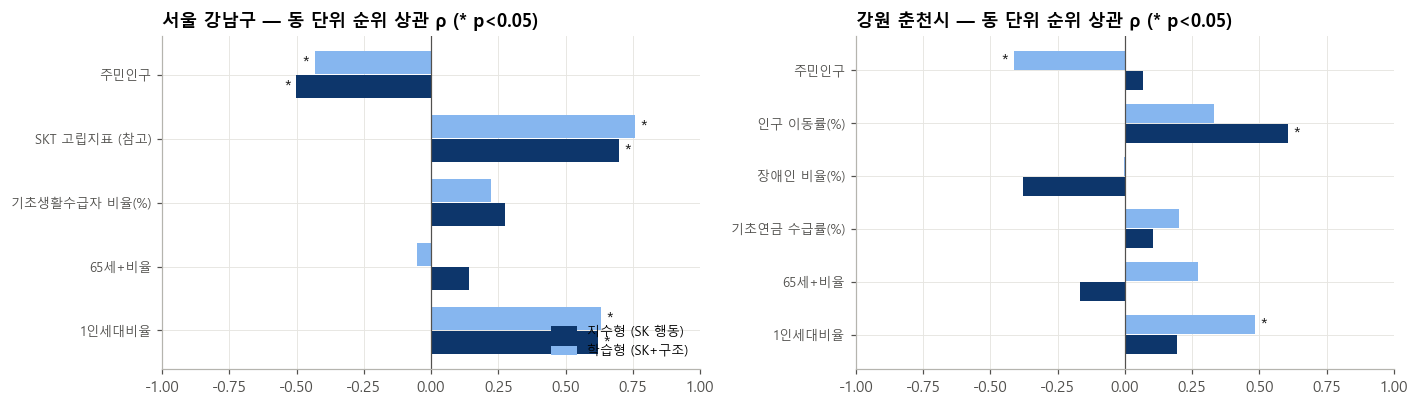

In [4]:
CRIT = [('1인세대비율', '수렴', '독립 (행정)'), ('65세+비율', '수렴', '독립 (행정)'), ('기초연금 수급률(%)', '수렴', '독립 (행정)'),
        ('장애인 비율(%)', '수렴', '독립 (행정)'), ('인구 이동률(%)', '수렴', '독립 (행정)'), ('기초생활수급자 비율(%)', '수렴', '독립 (행정)'),
        ('SKT 고립지표 (참고)', '수렴', '같은 출처'), ('주민인구', '판별', '독립 (행정)')]
rows = []
for reg in MAIN:
    d = D[D['지역'] == reg]
    for c, kind, src in CRIT:
        dd = d.dropna(subset=[c])
        if len(dd) < 5: continue
        for mdl in ['지수형 (SK 행동)', '학습형 (SK+구조)']:
            r, p = spearmanr(dd[mdl], dd[c])
            rows.append({'지역': reg, '검증 지표': c, '종류': kind, '출처': src, '모델': mdl, 'ρ': r, 'p': p, 'n': len(dd)})
V = pd.DataFrame(rows)
VP = V.pivot_table(index=['지역', '검증 지표', '종류', '출처'], columns='모델', values=['ρ', 'p']).round(3)
display(VP)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharex=True)
for ax, reg in zip(axes, MAIN):
    v = V[V['지역'] == reg]; labs = list(dict.fromkeys(v['검증 지표'])); y = np.arange(len(labs))
    for i, (mdl, col) in enumerate([('지수형 (SK 행동)', '#0d366b'), ('학습형 (SK+구조)', '#86b6ef')]):
        vv = v[v['모델'] == mdl].set_index('검증 지표').reindex(labs)
        ax.barh(y + (i - .5) * .38, vv['ρ'], height=.36, color=col, label=mdl)
        for yy, (rr, pp) in enumerate(zip(vv['ρ'], vv['p'])):
            if pp < .05: ax.text(rr + (.02 if rr > 0 else -.02), yy + (i - .5) * .38, '*', va='center', ha='left' if rr > 0 else 'right', color=INK)
    ax.set_yticks(y, labs, fontsize=8.5); ax.axvline(0, color=INK2, lw=.8); ax.set_xlim(-1, 1); ax.set_title(f'{reg} — 동 단위 순위 상관 ρ (* p<0.05)')
axes[0].legend(fontsize=8.5, loc='lower right'); plt.tight_layout(); plt.show()

## 4. 강남 SKT 정답과의 비교 (참고) — 정답을 쓰지 않은 지수형이 얼마나 맞히나

> **왜** 정답 없이 만든 지수가 정답을 얼마나 맞히는지 보면 학습형이 과적합됐는지 알 수 있습니다.  
> **결과** 지수형 0.51로 학습형(0.49, 동 하나씩 빼고 검증)과 같은 수준입니다. 04의 결과가 SKT에 과적합된 산물이 아닙니다.


In [5]:
E = U[U['지역'] == '서울 강남구'].merge(T[['SGIS코드', '성별', '연령5', 'y_rel']], on=['SGIS코드', '성별', '연령5'])
res = {}
for nm, col in [('지수형 (정답 미사용)', 'R'), ('학습형 (전체로 학습, 참고)', 'SA')]:
    wr = np.array([spearmanr(g['y_rel'], g[col])[0] for _, g in E.groupby('cell')])
    bs = [np.random.default_rng(i).choice(wr, len(wr)).mean() for i in range(1000)]
    res[nm] = {'동 순위 ρ (같은 성·연령 안)': wr.mean(), '95% 구간': f'{np.percentile(bs, 2.5):.2f}~{np.percentile(bs, 97.5):.2f}'}
res['학습형 (동 하나씩 빼고 검증, 04 결과)'] = {'동 순위 ρ (같은 성·연령 안)': 0.485, '95% 구간': '0.33~0.63'}
pd.DataFrame(res).T

,동 순위 ρ (같은 성·연령 안),95% 구간
지수형 (정답 미사용),0.510,0.40~0.62
"학습형 (전체로 학습, 참고)",0.529,0.40~0.66
"학습형 (동 하나씩 빼고 검증, 04 결과)",0.485,0.33~0.63


## 5. 두 모델의 우선순위는 얼마나 겹치나

> **왜** 모델을 바꾸면 우선순위가 얼마나 달라지는지 확인합니다.  
> **결과** 최종 점수 상위 15%의 겹침은 강남 88%, 춘천 78%입니다. 큰 그림은 같습니다.


In [6]:
rows = []
for reg in MAIN:
    u = U[U['지역'] == reg]; n = int(len(u) * .15)
    a, b = set(u.nlargest(n, 'R').index), set(u.nlargest(n, 'SA').index)
    a2, b2 = set(u.nlargest(n, '지수형 점수').index), set(u.nlargest(n, '위험점수').index)
    rows.append({'지역': reg, '행동 점수 순위 상관': spearmanr(u['R'], u['SA'])[0], '행동 점수 상위 15% 겹침(%)': len(a & b) / n * 100,
                 '최종 점수 순위 상관': spearmanr(u['지수형 점수'], u['위험점수'])[0], '최종 점수 상위 15% 겹침(%)': len(a2 & b2) / n * 100})
display(pd.DataFrame(rows).set_index('지역').round(2))
for reg in MAIN:
    u = U[U['지역'] == reg]
    only_idx = u.nlargest(int(len(u) * .15), '지수형 점수').index.difference(u.nlargest(int(len(u) * .15), '위험점수').index)
    print(f'[{reg}] 지수형에서만 상위 15%에 드는 집단:'); display(u.loc[only_idx, ['읍면동명', '성별', '연령5', '주민', '지수형 점수', '위험점수']].round(1).head(8))

,행동 점수 순위 상관,행동 점수 상위 15% 겹침(%),최종 점수 순위 상관,최종 점수 상위 15% 겹침(%)
지역,,,,
서울 강남구,0.930,69.700,0.970,87.880
강원 춘천시,0.820,67.570,0.960,78.380


[서울 강남구] 지수형에서만 상위 15%에 드는 집단:


,읍면동명,성별,연령5,주민,지수형 점수,위험점수
66,청담동,여성,60대+,3574,44.900,43.400
71,일원1동,남성,50대,978,44.700,42.900
95,일원1동,남성,60대+,2171,45.000,41.600
104,대치1동,여성,60대+,2121,44.900,40.500


[강원 춘천시] 지수형에서만 상위 15%에 드는 집단:


,읍면동명,성별,연령5,주민,지수형 점수,위험점수
83,강남동,여성,60대+,3952,42.200,42.300
89,효자2동,여성,50대,689,40.300,41.900
90,약사명동,여성,50대,348,40.800,41.900
91,후평2동,남성,60대+,1587,42.100,41.800
96,강남동,남성,50대,2045,40.300,41.500
99,퇴계동,여성,60대+,7040,43.700,41.100
110,후평1동,여성,50대,813,40.300,40.000
114,후평3동,남성,60대+,2542,40.600,39.700


## 6. 요약 · 기존(04 학습형)과의 차이

> **왜** 기존과의 차이와 설계 변경 방향을 정리합니다.  
> **결과** 주 모델을 지수형으로 전환하고, 위험도를 '행동 고립 × 사회경제 취약' 2축으로 나누는 것을 제안합니다.


### 한 줄 요약
**SKT 정답을 전혀 쓰지 않고 이론으로만 만든 지수가, 정답으로 학습한 모델과 같은 수준으로 정답을 맞혔고(ρ 0.51 vs 0.49), 두 지역 모두 출처가 다른 행정 지표와도 같은 방향으로 움직였습니다.** 다만 이 지수는 '머무는 방식'으로 드러나는 고립만 잡고, 경제·돌봄 취약형 고립은 잡지 못합니다.

### 기존(04 학습형)과 비교
| 비교 항목 | 04 학습형 | 04b 지수형 | 의미 |
|---|---|---|---|
| SKT 정답 사용 | 학습에 사용 | **사용 안 함** | 순환 문제 제거 |
| 강남 SKT 정답 맞힘 (동 순위 ρ) | 0.49 (동 하나씩 빼고 검증) | **0.51** (학습 없음) | 정답 없이도 같은 성능 → 04의 결과가 'SKT에 과적합된 산물'이 아님 |
| 강남 독립 지표: 1인 세대 비율 | 0.63 (입력에 1인 세대가 있어 부풀려짐) | **0.62** (입력에 없음) | 지수형 쪽이 더 깨끗한 근거 |
| 춘천 독립 지표: 인구 이동률 | 0.33 (유의하지 않음) | **0.61** (p=0.001) | **춘천도 처음으로 독립 검증됨** |
| 춘천 독립 지표: 1인 세대 비율 | 0.48 (부풀려짐) | 0.20 (유의하지 않음) | 춘천에서는 1인 세대보다 '이동이 잦은 동'과 연결 |
| 춘천: 기초연금 수급률·장애인 비율 | 0.20 / 0.00 | 0.10 / −0.38 | **경제·돌봄 취약과는 무관하거나 반대** |
| 강남: 기초생활수급자 비율 (2024.12) | 0.22 | 0.27 | 둘 다 유의하지 않음 → **강남에서도 경제 취약과 거의 무관** (수급자는 수서·일원1·개포3·세곡동 임대 단지에 집중) |
| 판별 (인구 규모와 무관해야 함) | 강남 −0.43, 춘천 −0.41 | 강남 **−0.50**, 춘천 0.07 | 강남에서는 **작은 동일수록 점수가 높아지는 편향**이 둘 다 있음 |
| 우선순위 겹침 (최종 점수 상위 15%) | — | 강남 88%, 춘천 78% | 큰 그림은 같고, 지수형은 일원1·대치1·청담동 고령층과 춘천 퇴계·후평동 고령층을 새로 끌어올림 |

### 쉽게 풀면
1. **"정답에 맞춰 외운 것 아니냐"는 의심이 풀렸습니다.** 정답을 보지 않고 '동네에 오래 머물고, 겨울에도 머무는 집단일수록 위험'이라는 이론만으로 점수를 매겼는데, 정답을 보고 학습한 모델만큼 맞혔습니다.
2. **춘천을 버리지 않게 됐습니다.** 춘천에는 SKT 정답이 없지만, 춘천시 통계연보의 인구 이동률과 강하게 연결돼 처음으로 독립 근거가 생겼습니다.
3. **이 지수가 재는 고립의 '종류'가 드러났습니다.**
   - 이 지수가 잡는 것: 1인 세대가 많고(강남) 주민이 자주 바뀌는(춘천) 곳, 즉 관계망이 약한 **'이동·단절형' 고립**
   - 이 지수가 못 잡는 것: 기초연금 수급률·장애인 비율이 높은 **'경제·돌봄 취약형' 고립**. 장애인 비율과는 오히려 반대(−0.38)인데, 돌봄이 필요한 사람은 이동이 적어 유동인구 자체가 작게 잡히기 때문일 수 있습니다(추정).
4. **고칠 점이 하나 보였습니다.** 강남에서 '주민 수가 적은 동일수록 점수가 높은' 경향(−0.50)이 있습니다. 비율 지표(유동 ÷ 거주)의 분모가 작아서 생기는 착시일 수 있어, 동 규모를 보정해야 합니다.

### 이 결과로 바뀌는 설계 (제안)
- **주 모델을 지수형으로 전환**: 순환이 없고, 두 지역에 같은 규칙을 쓰고, 근거를 설명하기 쉽습니다. 학습형은 '검증용 비교 모델'로 남깁니다.
- **위험도를 2축으로**:
  - (가) **행동 고립** — SK·카드, 이 지수
  - (나) **사회경제 취약** — 기초연금·장애인·수급자 같은 행정 지표
  - 두 축이 모두 높은 동·집단을 최우선으로 둡니다. 유형에 따라 연계할 복지자원도 달라집니다: 행동형 → 관계망·커뮤니티 프로그램, 취약형 → 기초생활·돌봄 서비스. 05·06 설계로 바로 이어집니다.
  - 주의: (나)에 쓴 행정 지표는 (가)의 검증에 다시 쓰지 않습니다.
- **동 규모 편향 보정**: 비율 지표를 동 인구 규모로 보정한 뒤 판별 검증을 다시 합니다.

### 한계
- 동 단위 검증이라 표본이 지역별 22~25개입니다. 여러 지표를 동시에 봤으므로 p<0.05 하나하나보다 전체 패턴으로 판단해야 합니다.
- 지표의 방향(위험이 높아지는 쪽)은 이론으로 정했지만, '유동/거주 비가 높을수록 위험'은 강남처럼 방문객이 많은 곳에서 오해의 여지가 있습니다.
- 강남 수급자 자료는 2024.12 기준이고, 비율의 분모는 2026.9 주민등록 인구라 시점이 다릅니다. 강남에서 1인 세대 비율과 수급자 비율의 상관이 0.79로 높아, 강남의 '1인 세대' 신호는 상당 부분 저소득 1인가구를 반영합니다.